# 03 — Correlacao e Relacoes Entre Variaveis

**Objetivos de aprendizagem:** distinguir associação e causalidade e usar covariância, Pearson, Spearman e dispersão

**Pré-requisitos:** Notebook 02

**Origem:** Slides, aula 04, páginas 93–119; aprofundamento: Spearman. Conteúdos adicionais estão identificados como **Aprofundamento**.

**Convenção:** `datasets/` reúne dados de entrada; `outputs/` reúne resultados. Dados inventados para demonstrações são sempre identificados como *sintéticos*.

### Materiais complementares

- [Guia Técnico](./reference_materials/03_correlacao_e_relacoes_entre_variaveis.pdf)
- [Cheat Sheet](./cheat_sheets/cheat_sheet_correlacao_e_relacoes_entre_variaveis.pdf)


## Preparação do ambiente

Execute a célula abaixo. Os notebooks são independentes e não dependem de variáveis definidas em outros arquivos.

> **Resultados reproduzíveis:** gráficos PNG e tabelas CSV selecionados são gravados automaticamente em `outputs/` ao executar as células na ordem. Os arquivos em `datasets/` são preservados. Esta disciplina usa Matplotlib, não o renderer `iframe` do Plotly.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Execute o JupyterLab com o diretório desta disciplina como raiz.
BASE = Path.cwd()
DATASETS = BASE / "datasets"
OUTPUTS = BASE / "outputs"
DATASETS.mkdir(parents=True, exist_ok=True)
OUTPUTS.mkdir(parents=True, exist_ok=True)

def ler_dataset(nome):
    caminho = DATASETS / nome
    if not caminho.is_file():
        raise FileNotFoundError(f"Dataset não encontrado: {caminho}. Abra o JupyterLab na raiz da disciplina.")
    return pd.read_csv(caminho)

RNG = np.random.default_rng(42)

## 1. Dispersão e covariância

A covariância mede como duas variáveis variam conjuntamente, mas depende das unidades. A correlação de Pearson padroniza essa relação entre −1 e +1, captando associação *linear*.

covariância 74.44228196283753
Pearson 0.9466036229171719


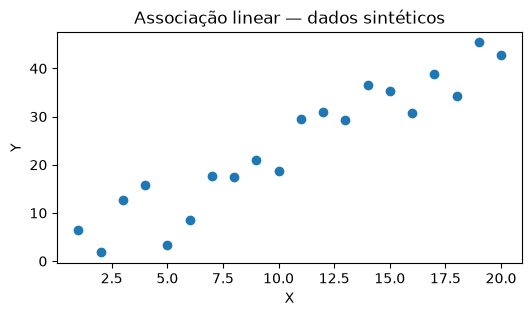

In [2]:
x=np.arange(1.,21.)
y=3+2*x+RNG.normal(0,5,size=x.size) # dados sintéticos
amostra=pd.DataFrame({'x':x,'y':y})
print('covariância',amostra.cov().iloc[0,1]);print('Pearson',amostra.corr(method='pearson').iloc[0,1])
fig,ax=plt.subplots(figsize=(6,3));ax.scatter(x,y);ax.set(xlabel='X',ylabel='Y',title='Associação linear — dados sintéticos');fig.savefig(OUTPUTS / '03_dispersao_linear.png', dpi=160, bbox_inches='tight');plt.show()

In [3]:
# Exportação reproduzível para outputs/ (dados e resultados didáticos)
amostra.to_csv(OUTPUTS / '03_dados_sinteticos_correlacao.csv',index=False,encoding='utf-8-sig')
print('Resultados exportados em:', OUTPUTS)

Resultados exportados em: /run/media/eduardo/Backup/Faculdades/PUC - CIENCIA DE DADOS/PUC/02_Disciplinas/03_statistics/outputs


## 2. Associação monotônica — Spearman (aprofundamento)

Spearman aplica Pearson aos postos: detecta tendências monotônicas inclusive quando a associação não é linear. Empates recebem postos médios em implementações comuns.

Pearson: 0.9713482021963805 Spearman: 1.0


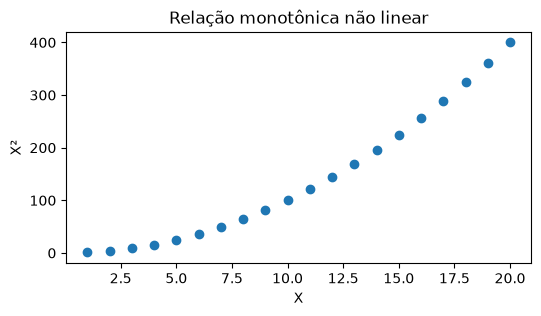

In [4]:
from scipy import stats
curva=x**2
print('Pearson:',stats.pearsonr(x,curva).statistic,'Spearman:',stats.spearmanr(x,curva).statistic)
fig,ax=plt.subplots(figsize=(6,3));ax.scatter(x,curva);ax.set(title='Relação monotônica não linear',xlabel='X',ylabel='X²');fig.savefig(OUTPUTS / '03_relacao_mono_nao_linear.png', dpi=160, bbox_inches='tight');plt.show()

## 3. Correlação espúria e confundimento

Correlação não implica causalidade. Uma terceira variável pode influenciar as duas medidas. Estratificar é útil para investigação, mas não garante identificação causal.

In [5]:
# Demonstração sintética: grupos deslocados de modo semelhante
x1=RNG.normal(0,1,100);x2=RNG.normal(5,1,100)
y1=RNG.normal(0,1,100);y2=RNG.normal(5,1,100)
d=pd.DataFrame({'x':np.r_[x1,x2],'y':np.r_[y1,y2],'grupo':['A']*100+['B']*100})
print('correlação agregada',round(d.x.corr(d.y),3));print('por grupo',d.groupby('grupo').apply(lambda g:g.x.corr(g.y),include_groups=False).round(3))

correlação agregada 0.866
por grupo grupo
A   -0.070
B   -0.046
dtype: float64


In [6]:
# Exportação reproduzível para outputs/ (dados e resultados didáticos)
d.groupby('grupo').apply(lambda g: g['x'].corr(g['y']),include_groups=False).rename('pearson').to_csv(OUTPUTS / '03_correlacao_por_grupo.csv',encoding='utf-8-sig')
print('Resultados exportados em:', OUTPUTS)

Resultados exportados em: /run/media/eduardo/Backup/Faculdades/PUC - CIENCIA DE DADOS/PUC/02_Disciplinas/03_statistics/outputs


## 4. Reta de mínimos quadrados: fundamento apenas

Uma regressão linear simples estima uma reta minimizando a soma dos resíduos quadráticos. Aqui ela serve para compreender inclinação e resíduos; treino, validação e regularização ficam para Aprendizado de Máquina.

intercepto e inclinação 1.502654957075162 2.1269223417953573 média dos resíduos -3.730349362740526e-15


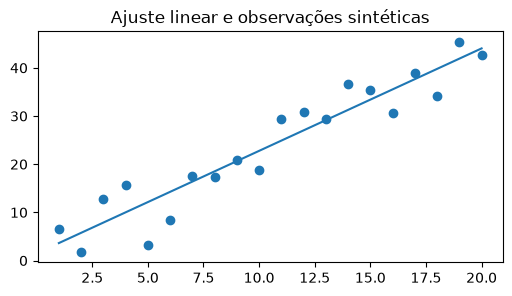

In [7]:
coef=np.polyfit(x,y,1);prev=np.polyval(coef,x);res=y-prev
print('intercepto e inclinação',coef[1],coef[0],'média dos resíduos',res.mean())
fig,ax=plt.subplots(figsize=(6,3));ax.scatter(x,y);ax.plot(x,prev);ax.set(title='Ajuste linear e observações sintéticas');fig.savefig(OUTPUTS / '03_ajuste_linear.png', dpi=160, bbox_inches='tight');plt.show()

In [8]:
# Exportação reproduzível para outputs/ (dados e resultados didáticos)
pd.DataFrame({'x':x,'y_observado':y,'y_ajustado':prev,'residuo':res}).to_csv(OUTPUTS / '03_ajuste_linear.csv',index=False,encoding='utf-8-sig')
print('Resultados exportados em:', OUTPUTS)

Resultados exportados em: /run/media/eduardo/Backup/Faculdades/PUC - CIENCIA DE DADOS/PUC/02_Disciplinas/03_statistics/outputs


### Exercício resolvido — Verificar o intervalo da correlação

**Solução comentada:**

In [9]:
r=stats.pearsonr(x,y).statistic
assert -1<=r<=1
print('r =',round(r,3),'r² =',round(r**2,3))

r = 0.947 r² = 0.896


**Interpretação:** Em regressão linear simples com intercepto, R² coincide com o quadrado de Pearson; fora desse contexto não assuma essa equivalência.

## Erros comuns e limites

Correlação não implica causalidade, valores-p não corrigem vieses do desenho e relações não lineares podem apresentar Pearson próximo de zero.

## Consulta Rápida

`df.cov()` · `df.corr(method="pearson")` · `stats.pearsonr(x,y)` · `stats.spearmanr(x,y)` · `np.polyfit(x,y,1)`.

## Autoavaliação

Antes de seguir, explique com suas palavras: **qual é a pergunta estatística, qual método responde a ela, quais pressupostos devem ser verificados e o que não podemos concluir?**

## Aprofundamento v2 — Incerteza da correlação e confundimento

A correlação de Pearson mede associação **linear** e não prova causalidade. Outliers, restrição de amplitude, dependência temporal e subgrupos podem distorcer a estimativa. O intervalo de confiança via transformação de Fisher é aproximado sob amostragem independente e normalidade bivariada, e não resolve vieses de desenho.

Para `r` e tamanho `n > 3`, use `z = arctanh(r)` e erro padrão aproximado `1/sqrt(n-3)`.

In [10]:
from scipy import stats
rng_extra = np.random.default_rng(2026)
x_corr = rng_extra.normal(size=90)
y_corr = 0.5*x_corr + rng_extra.normal(size=90)
r_corr = stats.pearsonr(x_corr, y_corr).statistic
z_corr = np.arctanh(r_corr)
se_z = 1/np.sqrt(len(x_corr)-3)
ic_r = np.tanh([z_corr-1.96*se_z, z_corr+1.96*se_z])
print(f'Correlação de Pearson: {r_corr:.3f}; IC95% aproximado: [{ic_r[0]:.3f}, {ic_r[1]:.3f}]')
assert ic_r[0] < r_corr < ic_r[1]

Correlação de Pearson: 0.307; IC95% aproximado: [0.107, 0.484]


### Exercício resolvido

**Pergunta:** dois indicadores crescem com o tempo e têm `r = 0,92`. Podemos afirmar que um causa o outro?

**Solução:** não. Tendência temporal comum pode gerar associação espúria; investigue série temporal, mecanismos causais, confundidores e desenho do estudo.